In [18]:
# Titanic Dataset Example: Data Analysis + Supervised Learning
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [19]:
# Step 1: Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

In [20]:
# Step 2: Quick look at data
print(df.head())
print(df.info())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

In [21]:
# Step 3: Data Analysis (EDA)
print("\nSurvival rate:")
print(df['Survived'].value_counts(normalize=True))


Survival rate:
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


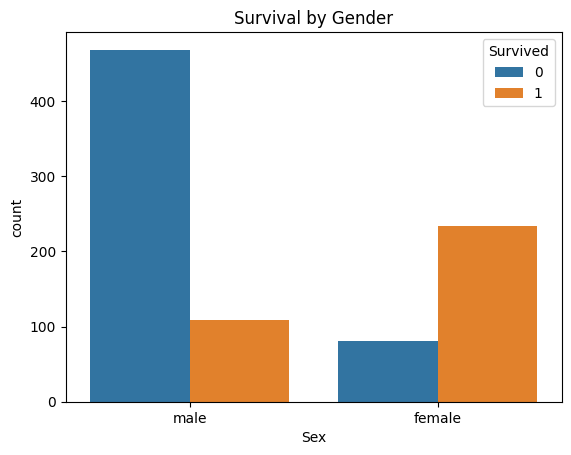

In [22]:
# Plot survival by gender
sns.countplot(x="Sex", hue="Survived", data=df)
plt.title("Survival by Gender")
plt.show()

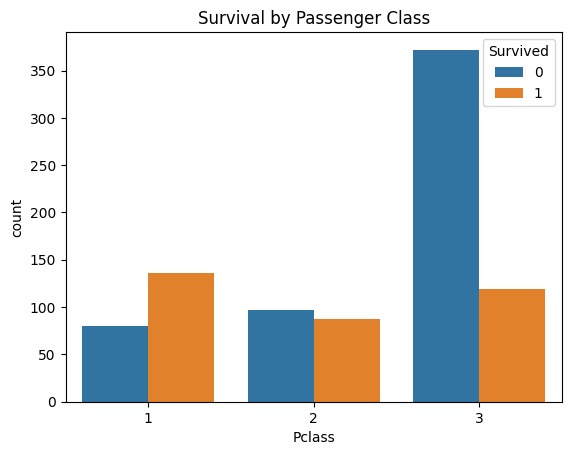

In [23]:
# Plot survival by passenger class
sns.countplot(x="Pclass", hue="Survived", data=df)
plt.title("Survival by Passenger Class")
plt.show()

In [24]:
# Step 4: Data Preprocessing
# Select useful features

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]
df = df[features + ["Survived"]]

In [25]:
# Handle missing values
df["Age"].fillna(df["Age"].median(), inplace=True)

C:\Users\yadav\AppData\Local\Temp\ipykernel_1808\3041482602.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Age"].fillna(df["Age"].median(), inplace=True)


In [26]:
# Encode categorical variable (Sex)
df["Sex"] = LabelEncoder().fit_transform(df["Sex"])

In [27]:
# Step 5: Train/Test split
X = df[features]
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [28]:
# Step 6: Train supervised model (Random Forest)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
# Step 7: Predictions and evaluation
y_pred = model.predict(X_test)


In [30]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8134328358208955

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.88      0.85       165
           1       0.79      0.70      0.74       103

    accuracy                           0.81       268
   macro avg       0.81      0.79      0.80       268
weighted avg       0.81      0.81      0.81       268



<>:15: SyntaxWarning: invalid escape sequence '\.'
<>:15: SyntaxWarning: invalid escape sequence '\.'
C:\Users\yadav\AppData\Local\Temp\ipykernel_1808\807385726.py:15: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df.Name.str.extract(' ([A-Za-z]+)\.', expand=False)
C:\Users\yadav\AppData\Local\Temp\ipykernel_1808\807385726.py:28: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the origina

Accuracy: 0.8134328358208955

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.92      0.86       165
           1       0.84      0.64      0.73       103

    accuracy                           0.81       268
   macro avg       0.82      0.78      0.79       268
weighted avg       0.82      0.81      0.81       268



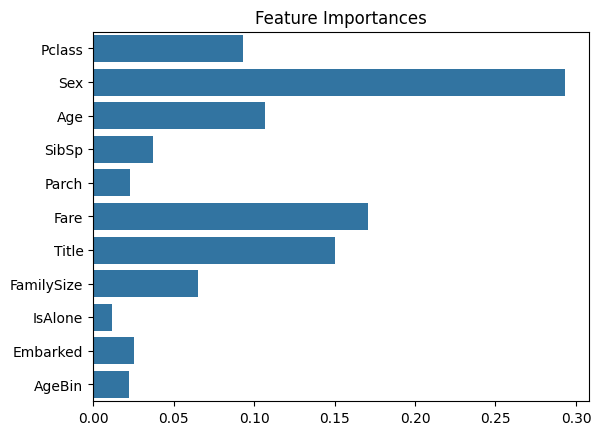

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Feature Engineering
# Extract Title from Name
df['Title'] = df.Name.str.extract(' ([A-Za-z]+)\.', expand=False)
df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col',\
                                   'Don', 'Dr', 'Major', 'Rev', 'Sir',\
                                   'Jonkheer', 'Dona'], 'Rare')
df['Title'] = df['Title'].replace('Mlle', 'Miss')
df['Title'] = df['Title'].replace('Ms', 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

# Create Family Size feature
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

# Create IsAlone feature
df['IsAlone'] = 1  # initialize to yes/1 is alone
df['IsAlone'].loc[df['FamilySize'] > 1] = 0

# Age bins - categorize age
df['Age'].fillna(df['Age'].median(), inplace=True)
bins = [0, 12, 18, 35, 60, 120]
labels = ['Child', 'Teen', 'Adult', 'MidAge', 'Senior']
df['AgeBin'] = pd.cut(df['Age'], bins, labels=labels)

# Fill Embarked missing values with most common port
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

# Fill Fare missing values with median Fare
df['Fare'].fillna(df['Fare'].median(), inplace=True)

# Encode categorical features
label_enc = LabelEncoder()
df['Sex'] = label_enc.fit_transform(df['Sex'])
df['Title'] = label_enc.fit_transform(df['Title'])
df['Embarked'] = label_enc.fit_transform(df['Embarked'])
df['AgeBin'] = label_enc.fit_transform(df['AgeBin'])

# Select features
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
            'Title', 'FamilySize', 'IsAlone', 'Embarked', 'AgeBin']

X = df[features]
y = df['Survived']

# Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

# Train RandomForest model with tuned parameters (example)
model = RandomForestClassifier(n_estimators=200, max_depth=7,
                               min_samples_split=5, random_state=42)
model.fit(X_train, y_train)

# Predictions and evaluation
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Optional: Plot feature importances
importances = model.feature_importances_
sns.barplot(x=importances, y=features)
plt.title("Feature Importances")
plt.show()


In [32]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load Titanic dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Feature Engineering
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)  # Fixed escape sequence warning
df['Title'] = df['Title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major',
                                   'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')

df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = 1
df.loc[df['FamilySize'] > 1, 'IsAlone'] = 0

# Handle missing values (no inplace or chained assignment)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Encode categorical features
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])
df['Title'] = le.fit_transform(df['Title'])
df['Embarked'] = le.fit_transform(df['Embarked'])

# Feature set and target
features = ['Pclass', 'Sex', 'Age', 'Fare', 'FamilySize', 'IsAlone', 'Title', 'Embarked']
X = df[features]
y = df['Survived']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# Define Random Forest model and hyperparameter grid
rf = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [4, 6, 8, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2']
}

# Use n_jobs=1 to avoid _posixsubprocess error on Windows
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    n_jobs=1,  # Important fix for Windows/Python 3.13
    verbose=1,
    scoring='accuracy'
)

# Fit model
grid_search.fit(X_train, y_train)

# Evaluate best model
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)

print("Best Parameters Found:", grid_search.best_params_)
print("Accuracy after tuning:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Fitting 5 folds for each of 324 candidates, totalling 1620 fits


C:\Users\yadav\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
540 fits failed out of a total of 1620.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
540 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\yadav\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\yadav\AppData\Local\Packages\PythonSoftwareFoun

Best Parameters Found: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}
Accuracy after tuning: 0.8022388059701493

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.88      0.85       165
           1       0.78      0.67      0.72       103

    accuracy                           0.80       268
   macro avg       0.80      0.78      0.78       268
weighted avg       0.80      0.80      0.80       268



In [33]:
# Advanced accuracy improvement: Ensemble modeling and more features
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# Feature Engineering
# Extract Title from Name
 df['Title'] = df.Name.str.extract(' ([A-Za-z]+)\.', expand=False)
 df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col',
                                    'Don', 'Dr', 'Major', 'Rev', 'Sir',
                                    'Jonkheer', 'Dona'], 'Rare')
 df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')

# Family features
 df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
 df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# Age bins
 df['Age'] = df['Age'].fillna(df['Age'].median())
 bins = [0, 12, 18, 35, 60, 120]
 labels = ['Child', 'Teen', 'Adult', 'MidAge', 'Senior']
 df['AgeBin'] = pd.cut(df['Age'], bins, labels=labels)

# Fill missing Embarked and Fare
 df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
 df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Encode categorical features
 le = LabelEncoder()
 df['Sex'] = le.fit_transform(df['Sex'])
 df['Title'] = le.fit_transform(df['Title'])
 df['Embarked'] = le.fit_transform(df['Embarked'])
 df['AgeBin'] = le.fit_transform(df['AgeBin'])

# Feature set
 features = ['Pclass', 'Sex', 'Age', 'Fare', 'FamilySize', 'IsAlone', 'Title', 'Embarked', 'AgeBin']
 X = df[features]
 y = df['Survived']

# Scale features for boosting
 scaler = StandardScaler()
 X_scaled = scaler.fit_transform(X)

# Train/test split
 X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, stratify=y, random_state=42)

# Ensemble: Voting Classifier
 rf = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_split=5, random_state=42)
 gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
 ensemble = VotingClassifier(estimators=[('rf', rf), ('gb', gb)], voting='soft')
 ensemble.fit(X_train, y_train)

# Predictions and evaluation
 y_pred = ensemble.predict(X_test)
 print("Ensemble Accuracy:", accuracy_score(y_test, y_pred))
 print("\nClassification Report:\n", classification_report(y_test, y_pred))

IndentationError: unexpected indent (308258888.py, line 15)